# 📓 Qdislib with IBM Quantum Cloud

In this notebook, we will demonstrate how to use **Qdislib** with **IBM Quantum Cloud** computers.  
Qdislib allows circuit partitioning and gate-cutting strategies to run larger quantum circuits than hardware natively supports.  
When `qpu=True`, Qdislib interfaces with IBM Quantum backends to execute quantum jobs on real quantum devices.

### 🔧 1. Environment Setup with IBM Quantum

Before using IBM Quantum resources, you need an IBM Quantum account. You can create one and obtain your API token from the official IBM Quantum platform:

🔗 [IBM Quantum Account Documentation](https://quantum.ibm.com/)

Once logged in, generate your **API Token** and retrieve:

- `token` — Your API token, `"<your-token>"`
- `instance` — Optional: The instance provider string
- `channel` — Usually `"ibm_quantum"`
- `quantum_chip` — Optional: the backend name like `"ibm_marrakesh"` or `"ibm_fez"`

### 🧠 2. Set Environment Variables in Python

Set the required environment variables directly in the notebook:


In [1]:
import os

# Replace with your actual IBM Quantum credentials
os.environ["IBM_QUANTUM_TOKEN"] = "<your_token>"
os.environ["IBM_QUANTUM_INSTANCE"] =  "<your_instance>" #optional
os.environ["IBM_QUANTUM_CHANNEL"] = "ibm_cloud"
os.environ["IBM_QUANTUM_MAX_TIME"] = "60" #optional
os.environ["IBM_QUANTUM_QPU_NAME"] = "ibm_marrakesh" # optional



Note:
* `"IBM_QUANTUM_MAX_TIME"` represents the maxium time in seconds the batch session will remain open

* If no specific IBM_QUANTUM_QPU_NAME is given, Qdislib will automatically select the least busy backend from the available IBM Quantum devices.
`backend = service.least_busy(operational=True, simulator=False)`

### ⚙️ 3. Using Qdislib with IBM Quantum

Now you're ready to use Qdislib. Here's an example of how to run a gate-cutting reconstruction on IBM Quantum hardware.

In [ ]:
import Qdislib as qd
from qiskit import QuantumCircuit

# Example circuit
circuit = QuantumCircuit(10)
circuit.cz(0,1)
circuit.cz(1,2)
circuit.cz(2,3)
circuit.cz(3,4)
circuit.cz(4,5)
circuit.cz(5,6)
circuit.cz(6,7)
circuit.cz(7,8)
circuit.cz(8,9)

circuit.measure_all()


# Define cut (as per Qdislib — adjust as needed)
cut = ["CZ_5"]

# QPU settings dictionary — only "IBM_Quantum" for, max number of qubits the chip has is 156
qpu_dict = {
    "IBM_Quantum": 156  # This number refers to the maximum number of qubits the QPU has
}

# Run gate cutting with QPU enabled
reconstruction = qd.gate_cutting(
    circuit,
    cut,
    qpu=True,
    qpu_dict=qpu_dict
)

print("Reconstuction ", reconstruction)

ibm_sherbrooke
['for_loop', 'rz', 'ecr', 'switch_case', 'delay', 'x', 'sx', 'reset', 'measure', 'if_else', 'id']
job id: d0q39bo15afs73clt09g
PrimitiveResult([SamplerPubResult(data=DataBin(c=BitArray(<shape=(), num_shots=4096, num_bits=5>), meas=BitArray(<shape=(), num_shots=4096, num_bits=5>)), metadata={'circuit_metadata': {}})], metadata={'execution': {'execution_spans': ExecutionSpans([DoubleSliceSpan(<start='2025-05-26 10:16:11', stop='2025-05-26 10:16:21', size=4096>)])}, 'version': 2})
{'00001': 1246, '10001': 568, '11001': 160, '10101': 309, '01001': 145, '00111': 161, '00101': 732, '00011': 251, '01101': 92, '11111': 24, '10011': 130, '01110': 1, '11101': 94, '10111': 62, '01111': 21, '11011': 30, '01011': 33, '00000': 12, '10100': 2, '10000': 4, '11010': 1, '01000': 2, '00110': 1, '00100': 8, '10010': 1, '11000': 1, '01100': 2, '00010': 3}
job id: d0q3uto15afs73cltklg
PrimitiveResult([SamplerPubResult(data=DataBin(c=BitArray(<shape=(), num_shots=4096, num_bits=5>), meas=BitAr

### ⏹️ 5. Summary

By following these steps:

* Set up an IBM Quantum account and API token

* Configure your environment variables

* Run your Qdislib gate-cutting circuits using real IBM Quantum hardware

You can now execute large quantum workloads on IBM’s cloud infrastructure via Qdislib’s automatic circuit cutting and reconstruction pipeline.

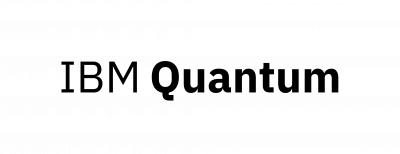

In [10]:
from PIL import Image
from IPython.display import display

img = Image.open('../docs/ibm_quantum_logo.png')

display(img)
